In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("employee_salary.csv")

In [ ]:
df = pd.read_csv("employee_salary.csv")

In [ ]:
df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2.0,109413.0
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0.0,93764.0
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1.0,148123.0
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0.0,189123.0
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0.0,165069.0


In [62]:
df[numeric_columns].describe()

,experience_years,skills_count,certifications,salary
count,15279.000000,15279.000000,15279.000000,15279.000000
mean,9.969566,9.994633,2.493946,145332.987696
std,6.062903,5.475012,1.722296,37220.209711
min,0.000000,1.000000,0.000000,41404.000000
25%,5.000000,5.000000,1.000000,118909.000000
50%,10.000000,10.000000,2.000000,142871.000000
75%,15.000000,15.000000,4.000000,169214.000000
max,20.000000,19.000000,5.000000,324505.000000


In [ ]:
df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2.0,109413.0
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0.0,93764.0
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1.0,148123.0
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0.0,189123.0
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0.0,165069.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15280 entries, 0 to 15279
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   job_title         15280 non-null  object 
 1   experience_years  15280 non-null  int64  
 2   education_level   15280 non-null  object 
 3   skills_count      15280 non-null  int64  
 4   industry          15279 non-null  object 
 5   company_size      15279 non-null  object 
 6   location          15279 non-null  object 
 7   remote_work       15279 non-null  object 
 8   certifications    15279 non-null  float64
 9   salary            15279 non-null  float64
dtypes: float64(2), int64(2), object(6)
memory usage: 1.2+ MB


In [ ]:
df.describe(include="all")

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
count,15280,15280.000000,15280,15280.000000,15279,15279,15279,15279,15279.000000,15279.000000
unique,12,NaN,5,NaN,10,5,10,3,NaN,NaN
top,Backend Developer,NaN,High School,NaN,Healthcare,Medium,Singapore,Hybrid,NaN,NaN
freq,1325,NaN,3185,NaN,1562,3107,1580,5126,NaN,NaN
mean,NaN,9.970092,NaN,9.994306,NaN,NaN,NaN,NaN,2.493946,145332.987696
std,NaN,6.063053,NaN,5.474982,NaN,NaN,NaN,NaN,1.722296,37220.209711
min,NaN,0.000000,NaN,1.000000,NaN,NaN,NaN,NaN,0.000000,41404.000000
25%,NaN,5.000000,NaN,5.000000,NaN,NaN,NaN,NaN,1.000000,118909.000000
50%,NaN,10.000000,NaN,10.000000,NaN,NaN,NaN,NaN,2.000000,142871.000000
75%,NaN,15.000000,NaN,15.000000,NaN,NaN,NaN,NaN,4.000000,169214.000000


In [ ]:
df.columns

Index(['job_title', 'experience_years', 'education_level', 'skills_count',
       'industry', 'company_size', 'location', 'remote_work', 'certifications',
       'salary'],
      dtype='object')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

# Plot settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
for column in df.columns:
    print("\n" + "=" * 50)
    print("COLUMN:", column)
    print("=" * 50)
    print(df[column].head(10))


COLUMN: job_title
0                  AI Engineer
1                 Data Analyst
2           Frontend Developer
3             Business Analyst
4              Product Manager
5                  AI Engineer
6            Backend Developer
7    Machine Learning Engineer
8                  AI Engineer
9           Frontend Developer
Name: job_title, dtype: object

COLUMN: experience_years
0    10
1     5
2    18
3    19
4    15
5     0
6     6
7     4
8     5
9    18
Name: experience_years, dtype: int64

COLUMN: education_level
0       Bachelor
1       Bachelor
2            PhD
3            PhD
4       Bachelor
5    High School
6    High School
7       Bachelor
8        Diploma
9            PhD
Name: education_level, dtype: object

COLUMN: skills_count
0     2
1    17
2     4
3    13
4     7
5     4
6    16
7    18
8    14
9     2
Name: skills_count, dtype: int64

COLUMN: industry
0       Healthcare
1          Telecom
2            Media
3           Retail
4    Manufacturing
5        Educatio

for column in df.columns:
    print("\n" + "=" * 50)
    print("COLUMN:", column)
    print("=" * 50)
    print(df[column].head(10))

In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing.sort_values(
    "Missing_Count",
    ascending=False
)

,Missing_Count,Missing_Percentage
industry,1,0.006545
company_size,1,0.006545
certifications,1,0.006545
salary,1,0.006545
remote_work,1,0.006545
location,1,0.006545
experience_years,0,0.000000
job_title,0,0.000000
education_level,0,0.000000
skills_count,0,0.000000


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
df.dtypes

,0
job_title,object
experience_years,int64
education_level,object
skills_count,int64
industry,object
company_size,object
location,object
remote_work,object
certifications,float64
salary,float64


In [ ]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns)

Index(['job_title', 'experience_years', 'education_level', 'skills_count',
       'industry', 'company_size', 'location', 'remote_work', 'certifications',
       'salary'],
      dtype='object')


In [ ]:
numeric_columns = [
    "experience_years",
    "skills_count",
    "certifications",
    "salary"
]

In [ ]:
df[numeric_columns].describe()

,experience_years,skills_count,certifications,salary
count,15280.000000,15280.000000,15279.000000,15279.000000
mean,9.970092,9.994306,2.493946,145332.987696
std,6.063053,5.474982,1.722296,37220.209711
min,0.000000,1.000000,0.000000,41404.000000
25%,5.000000,5.000000,1.000000,118909.000000
50%,10.000000,10.000000,2.000000,142871.000000
75%,15.000000,15.000000,4.000000,169214.000000
max,20.000000,19.000000,5.000000,324505.000000


In [ ]:
print("Negative experience:")
print(df[df["experience_years"] < 0])

Negative experience:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []


In [ ]:
print("Negative skills:")
print(df[df["skills_count"] < 0])

Negative skills:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []


In [ ]:
print("Negative certifications:")
print(df[df["certifications"] < 0])

Negative certifications:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []


In [ ]:
print("Invalid salary:")
print(df[df["salary"] <= 0])

Invalid salary:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []


In [ ]:
print("JOB TITLES")
print(df["job_title"].value_counts())

JOB TITLES
job_title
Backend Developer            1325
Data Scientist               1313
Cybersecurity Analyst        1307
DevOps Engineer              1302
AI Engineer                  1289
Machine Learning Engineer    1272
Cloud Engineer               1259
Product Manager              1257
Business Analyst             1256
Data Analyst                 1248
Software Engineer            1246
Frontend Developer           1206
Name: count, dtype: int64


In [ ]:
print("\nEDUCATION")
print(df["education_level"].value_counts())


EDUCATION
education_level
High School    3185
Diploma        3059
Bachelor       3041
Master         3017
PhD            2978
Name: count, dtype: int64


In [ ]:
print("\nINDUSTRY")
print(df["industry"].value_counts())


INDUSTRY
industry
Healthcare       1562
Retail           1560
Finance          1550
Telecom          1549
Consulting       1544
Government       1543
Education        1540
Media            1491
Manufacturing    1479
Technology       1461
Name: count, dtype: int64


In [ ]:
print("\nCOMPANY SIZE")
print(df["company_size"].value_counts())


COMPANY SIZE
company_size
Medium        3107
Startup       3075
Small         3067
Enterprise    3023
Large         3007
Name: count, dtype: int64


In [ ]:
print("\nLOCATION")
print(df["location"].value_counts())


LOCATION
location
Singapore      1580
UK             1568
Remote         1557
Australia      1539
Netherlands    1534
Canada         1519
Germany        1511
Sweden         1508
India          1484
USA            1479
Name: count, dtype: int64


In [ ]:
print("\nREMOTE WORK")
print(df["remote_work"].value_counts())


REMOTE WORK
remote_work
Hybrid    5126
Yes       5084
No        5069
Name: count, dtype: int64


In [ ]:
text_columns = [
    "job_title",
    "education_level",
    "industry",
    "company_size",
    "location",
    "remote_work"
]

for col in text_columns:
    print("\n", col)
    print(df[col].unique())


 job_title
['AI Engineer' 'Data Analyst' 'Frontend Developer' 'Business Analyst'
 'Product Manager' 'Backend Developer' 'Machine Learning Engineer'
 'DevOps Engineer' 'Software Engineer' 'Cybersecurity Analyst'
 'Data Scientist' 'Cloud Engineer']

 education_level
['Bachelor' 'PhD' 'High School' 'Diploma' 'Master']

 industry
['Healthcare' 'Telecom' 'Media' 'Retail' 'Manufacturing' 'Education'
 'Finance' 'Technology' 'Consulting' 'Government' nan]

 company_size
['Medium' 'Small' 'Large' 'Enterprise' 'Startup' nan]

 location
['India' 'Australia' 'Singapore' 'Canada' 'Sweden' 'USA' 'Netherlands'
 'Remote' 'Germany' 'UK' nan]

 remote_work
['Hybrid' 'No' 'Yes' nan]


In [ ]:
for col in text_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

In [ ]:
for col in text_columns:
    print("\n", col)
    print(df[col].unique())


 job_title
['ai engineer' 'data analyst' 'frontend developer' 'business analyst'
 'product manager' 'backend developer' 'machine learning engineer'
 'devops engineer' 'software engineer' 'cybersecurity analyst'
 'data scientist' 'cloud engineer']

 education_level
['bachelor' 'phd' 'high school' 'diploma' 'master']

 industry
['healthcare' 'telecom' 'media' 'retail' 'manufacturing' 'education'
 'finance' 'technology' 'consulting' 'government' 'nan']

 company_size
['medium' 'small' 'large' 'enterprise' 'startup' 'nan']

 location
['india' 'australia' 'singapore' 'canada' 'sweden' 'usa' 'netherlands'
 'remote' 'germany' 'uk' 'nan']

 remote_work
['hybrid' 'no' 'yes' 'nan']


In [ ]:
print(df.isnull().sum())

job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      1
salary              1
dtype: int64


In [ ]:
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (15280, 10)

Missing Values:
job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      1
salary              1
dtype: int64

Duplicate Rows:
0

Data Types:
job_title            object
experience_years      int64
education_level      object
skills_count          int64
industry             object
company_size         object
location             object
remote_work          object
certifications      float64
salary              float64
dtype: object


In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (15280, 10)

Missing Values:
job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      1
salary              1
dtype: int64

Duplicate Rows:
0

Data Types:
job_title            object
experience_years      int64
education_level      object
skills_count          int64
industry             object
company_size         object
location             object
remote_work          object
certifications      float64
salary              float64
dtype: object


In [ ]:
print(df.shape)

(15280, 10)


In [ ]:
print(df.isnull().sum())

job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      1
salary              1
dtype: int64


In [ ]:
# Check the rows with missing values
df[df["certifications"].isnull() | df["salary"].isnull()]

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
15279,business analyst,18,phd,5,nan,nan,nan,nan,NaN,NaN


In [ ]:
# Fill missing certifications with median
df["certifications"] = df["certifications"].fillna(
    df["certifications"].median()
)

# Remove the row where salary is missing
df = df.dropna(subset=["salary"])

print("Dataset Shape after cleaning:", df.shape)

Dataset Shape after cleaning: (15279, 10)


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
categorical_columns = [
    "job_title",
    "education_level",
    "industry",
    "company_size",
    "location",
    "remote_work"
]

for col in categorical_columns:
    print("\n" + "=" * 50)
    print(col.upper())
    print("=" * 50)
    print(df[col].value_counts())


JOB_TITLE
job_title
backend developer            1325
data scientist               1313
cybersecurity analyst        1307
devops engineer              1302
ai engineer                  1289
machine learning engineer    1272
cloud engineer               1259
product manager              1257
business analyst             1255
data analyst                 1248
software engineer            1246
frontend developer           1206
Name: count, dtype: int64

EDUCATION_LEVEL
education_level
high school    3185
diploma        3059
bachelor       3041
master         3017
phd            2977
Name: count, dtype: int64

INDUSTRY
industry
healthcare       1562
retail           1560
finance          1550
telecom          1549
consulting       1544
government       1543
education        1540
media            1491
manufacturing    1479
technology       1461
Name: count, dtype: int64

COMPANY_SIZE
company_size
medium        3107
startup       3075
small         3067
enterprise    3023
large         3007

In [ ]:
numeric_columns = [
    "experience_years",
    "skills_count",
    "certifications",
    "salary"
]

df[numeric_columns].describe()

,experience_years,skills_count,certifications,salary
count,15279.000000,15279.000000,15279.000000,15279.000000
mean,9.969566,9.994633,2.493946,145332.987696
std,6.062903,5.475012,1.722296,37220.209711
min,0.000000,1.000000,0.000000,41404.000000
25%,5.000000,5.000000,1.000000,118909.000000
50%,10.000000,10.000000,2.000000,142871.000000
75%,15.000000,15.000000,4.000000,169214.000000
max,20.000000,19.000000,5.000000,324505.000000


In [ ]:
print("Negative Experience:")
print(df[df["experience_years"] < 0])

print("\nNegative Skills:")
print(df[df["skills_count"] < 0])

print("\nNegative Certifications:")
print(df[df["certifications"] < 0])

print("\nZero/Negative Salary:")
print(df[df["salary"] <= 0])

Negative Experience:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []

Negative Skills:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []

Negative Certifications:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []

Zero/Negative Salary:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []


In [ ]:
print("===== SALARY STATISTICS =====")

print("Mean Salary   :", df["salary"].mean())
print("Median Salary :", df["salary"].median())
print("Minimum Salary:", df["salary"].min())
print("Maximum Salary:", df["salary"].max())
print("Std Deviation :", df["salary"].std())

print("\n===== EXPERIENCE STATISTICS =====")

print("Mean Experience   :", df["experience_years"].mean())
print("Median Experience :", df["experience_years"].median())
print("Minimum Experience:", df["experience_years"].min())
print("Maximum Experience:", df["experience_years"].max())

print("\n===== SKILLS STATISTICS =====")

print("Mean Skills   :", df["skills_count"].mean())
print("Median Skills :", df["skills_count"].median())
print("Maximum Skills:", df["skills_count"].max())

print("\n===== CERTIFICATION STATISTICS =====")

print("Mean Certifications   :", df["certifications"].mean())
print("Median Certifications :", df["certifications"].median())
print("Maximum Certifications:", df["certifications"].max())

===== SALARY STATISTICS =====
Mean Salary   : 145332.98769552982
Median Salary : 142871.0
Minimum Salary: 41404.0
Maximum Salary: 324505.0
Std Deviation : 37220.20971099006

===== EXPERIENCE STATISTICS =====
Mean Experience   : 9.969566071077951
Median Experience : 10.0
Minimum Experience: 0
Maximum Experience: 20

===== SKILLS STATISTICS =====
Mean Skills   : 9.994633156620198
Median Skills : 10.0
Maximum Skills: 19

===== CERTIFICATION STATISTICS =====
Mean Certifications   : 2.493945938870345
Median Certifications : 2.0
Maximum Certifications: 5.0


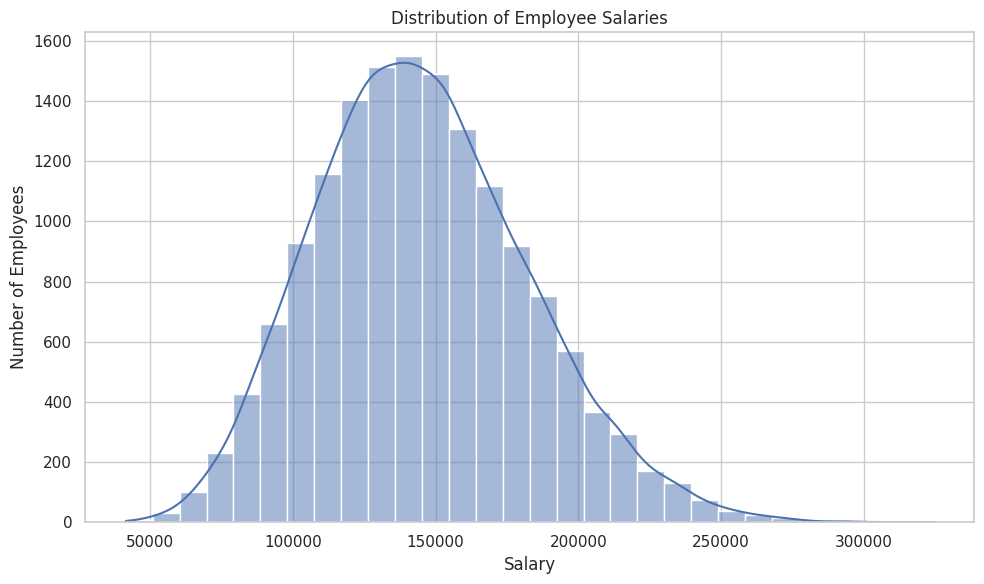

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="salary",
    bins=30,
    kde=True
)

plt.title("Distribution of Employee Salaries")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

In [ ]:
job_salary = (
    df.groupby("job_title")["salary"]
    .agg(
        employee_count="count",
        average_salary="mean",
        median_salary="median",
        minimum_salary="min",
        maximum_salary="max",
        salary_std="std"
    )
    .sort_values("average_salary", ascending=False)
)

job_salary

,employee_count,average_salary,median_salary,minimum_salary,maximum_salary,salary_std
job_title,,,,,,
ai engineer,1289,172823.366951,172209.0,77916.0,324505.0,37101.421038
machine learning engineer,1272,163207.503931,161014.5,66351.0,278283.0,37359.614152
product manager,1257,157554.210024,155085.0,67132.0,293673.0,36019.394790
cloud engineer,1259,150478.502780,148843.0,63073.0,292855.0,35008.262476
devops engineer,1302,150029.070661,148001.5,55689.0,271872.0,33983.240236
cybersecurity analyst,1307,147619.485080,146086.0,60172.0,275896.0,33300.340611
data scientist,1313,147036.159177,144182.0,61499.0,271515.0,34853.429977
software engineer,1246,141029.933387,138370.5,56693.0,264674.0,33464.977377
backend developer,1325,138720.603774,136011.0,51680.0,278642.0,33379.263451


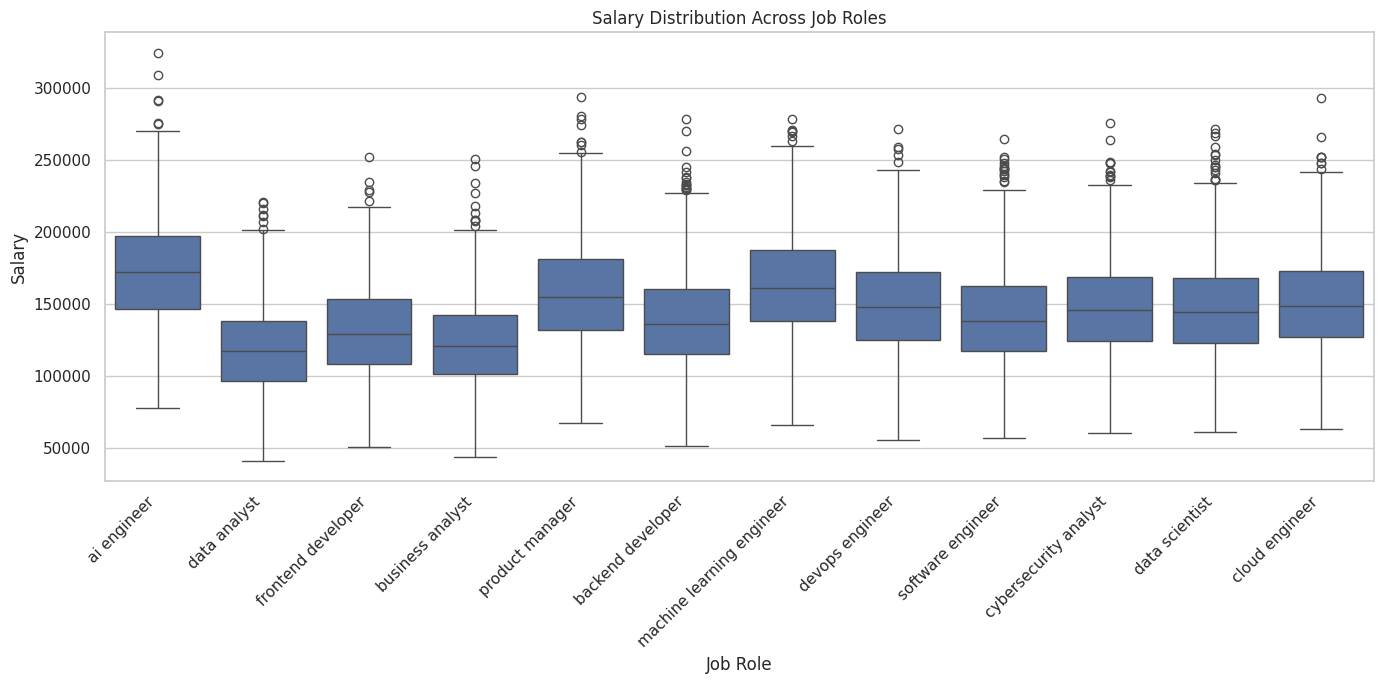

In [ ]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="job_title",
    y="salary"
)

plt.title("Salary Distribution Across Job Roles")
plt.xlabel("Job Role")
plt.ylabel("Salary")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
df[numeric_columns].describe()

,experience_years,skills_count,certifications,salary
count,15279.000000,15279.000000,15279.000000,15279.000000
mean,9.969566,9.994633,2.493946,145332.987696
std,6.062903,5.475012,1.722296,37220.209711
min,0.000000,1.000000,0.000000,41404.000000
25%,5.000000,5.000000,1.000000,118909.000000
50%,10.000000,10.000000,2.000000,142871.000000
75%,15.000000,15.000000,4.000000,169214.000000
max,20.000000,19.000000,5.000000,324505.000000


In [ ]:
print("Negative Experience:")
print(df[df["experience_years"] < 0])

print("\nNegative Skills:")
print(df[df["skills_count"] < 0])

print("\nNegative Certifications:")
print(df[df["certifications"] < 0])

print("\nZero/Negative Salary:")
print(df[df["salary"] <= 0])

Negative Experience:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []

Negative Skills:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []

Negative Certifications:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []

Zero/Negative Salary:
Empty DataFrame
Columns: [job_title, experience_years, education_level, skills_count, industry, company_size, location, remote_work, certifications, salary]
Index: []


In [ ]:
numeric_columns = [
    "experience_years",
    "skills_count",
    "certifications",
    "salary"
]

df[numeric_columns].describe()

,experience_years,skills_count,certifications,salary
count,15279.000000,15279.000000,15279.000000,15279.000000
mean,9.969566,9.994633,2.493946,145332.987696
std,6.062903,5.475012,1.722296,37220.209711
min,0.000000,1.000000,0.000000,41404.000000
25%,5.000000,5.000000,1.000000,118909.000000
50%,10.000000,10.000000,2.000000,142871.000000
75%,15.000000,15.000000,4.000000,169214.000000
max,20.000000,19.000000,5.000000,324505.000000


In [ ]:
print("===== SALARY ANALYSIS =====")

print(f"Average Salary : {df['salary'].mean():,.2f}")
print(f"Median Salary  : {df['salary'].median():,.2f}")
print(f"Minimum Salary : {df['salary'].min():,.2f}")
print(f"Maximum Salary : {df['salary'].max():,.2f}")
print(f"Std Deviation  : {df['salary'].std():,.2f}")

===== SALARY ANALYSIS =====
Average Salary : 145,332.99
Median Salary  : 142,871.00
Minimum Salary : 41,404.00
Maximum Salary : 324,505.00
Std Deviation  : 37,220.21


In [ ]:
print("===== SKILLS =====")

print(f"Average Skills : {df['skills_count'].mean():.2f}")
print(f"Median Skills  : {df['skills_count'].median():.2f}")
print(f"Maximum Skills : {df['skills_count'].max():.2f}")

print("\n===== CERTIFICATIONS =====")

print(f"Average Certifications : {df['certifications'].mean():.2f}")
print(f"Median Certifications  : {df['certifications'].median():.2f}")
print(f"Maximum Certifications : {df['certifications'].max():.2f}")

===== SKILLS =====
Average Skills : 9.99
Median Skills  : 10.00
Maximum Skills : 19.00

===== CERTIFICATIONS =====
Average Certifications : 2.49
Median Certifications  : 2.00
Maximum Certifications : 5.00


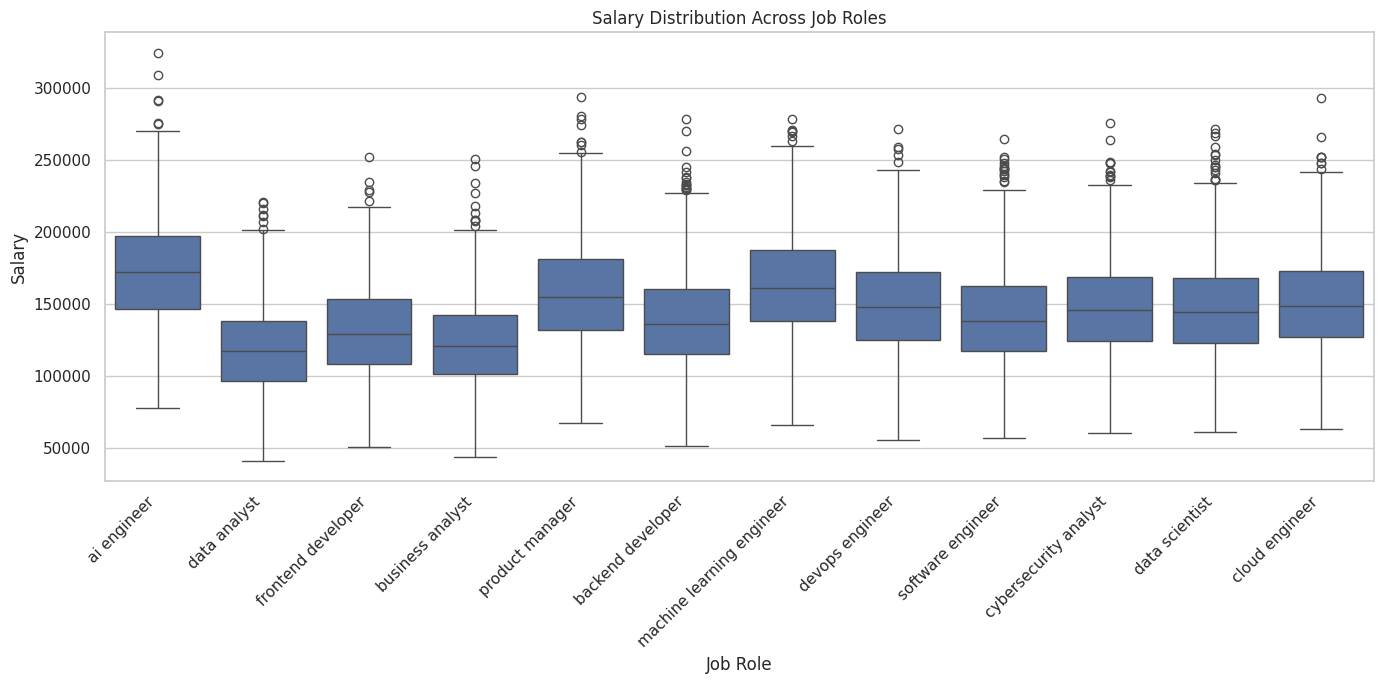

In [ ]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="job_title",
    y="salary"
)

plt.title("Salary Distribution Across Job Roles")
plt.xlabel("Job Role")
plt.ylabel("Salary")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [63]:
df[numeric_columns].describe()

,experience_years,skills_count,certifications,salary
count,15279.000000,15279.000000,15279.000000,15279.000000
mean,9.969566,9.994633,2.493946,145332.987696
std,6.062903,5.475012,1.722296,37220.209711
min,0.000000,1.000000,0.000000,41404.000000
25%,5.000000,5.000000,1.000000,118909.000000
50%,10.000000,10.000000,2.000000,142871.000000
75%,15.000000,15.000000,4.000000,169214.000000
max,20.000000,19.000000,5.000000,324505.000000


In [64]:
print("===== SALARY ANALYSIS =====")
print(f"Average Salary : {df['salary'].mean():,.2f}")
print(f"Median Salary  : {df['salary'].median():,.2f}")
print(f"Minimum Salary : {df['salary'].min():,.2f}")
print(f"Maximum Salary : {df['salary'].max():,.2f}")
print(f"Std Deviation  : {df['salary'].std():,.2f}")

===== SALARY ANALYSIS =====
Average Salary : 145,332.99
Median Salary  : 142,871.00
Minimum Salary : 41,404.00
Maximum Salary : 324,505.00
Std Deviation  : 37,220.21


In [65]:
job_salary = (
    df.groupby("job_title")["salary"]
    .agg(
        employee_count="count",
        average_salary="mean",
        median_salary="median",
        minimum_salary="min",
        maximum_salary="max",
        salary_std="std"
    )
    .sort_values("average_salary", ascending=False)
)

job_salary

,employee_count,average_salary,median_salary,minimum_salary,maximum_salary,salary_std
job_title,,,,,,
ai engineer,1289,172823.366951,172209.0,77916.0,324505.0,37101.421038
machine learning engineer,1272,163207.503931,161014.5,66351.0,278283.0,37359.614152
product manager,1257,157554.210024,155085.0,67132.0,293673.0,36019.394790
cloud engineer,1259,150478.502780,148843.0,63073.0,292855.0,35008.262476
devops engineer,1302,150029.070661,148001.5,55689.0,271872.0,33983.240236
cybersecurity analyst,1307,147619.485080,146086.0,60172.0,275896.0,33300.340611
data scientist,1313,147036.159177,144182.0,61499.0,271515.0,34853.429977
software engineer,1246,141029.933387,138370.5,56693.0,264674.0,33464.977377
backend developer,1325,138720.603774,136011.0,51680.0,278642.0,33379.263451


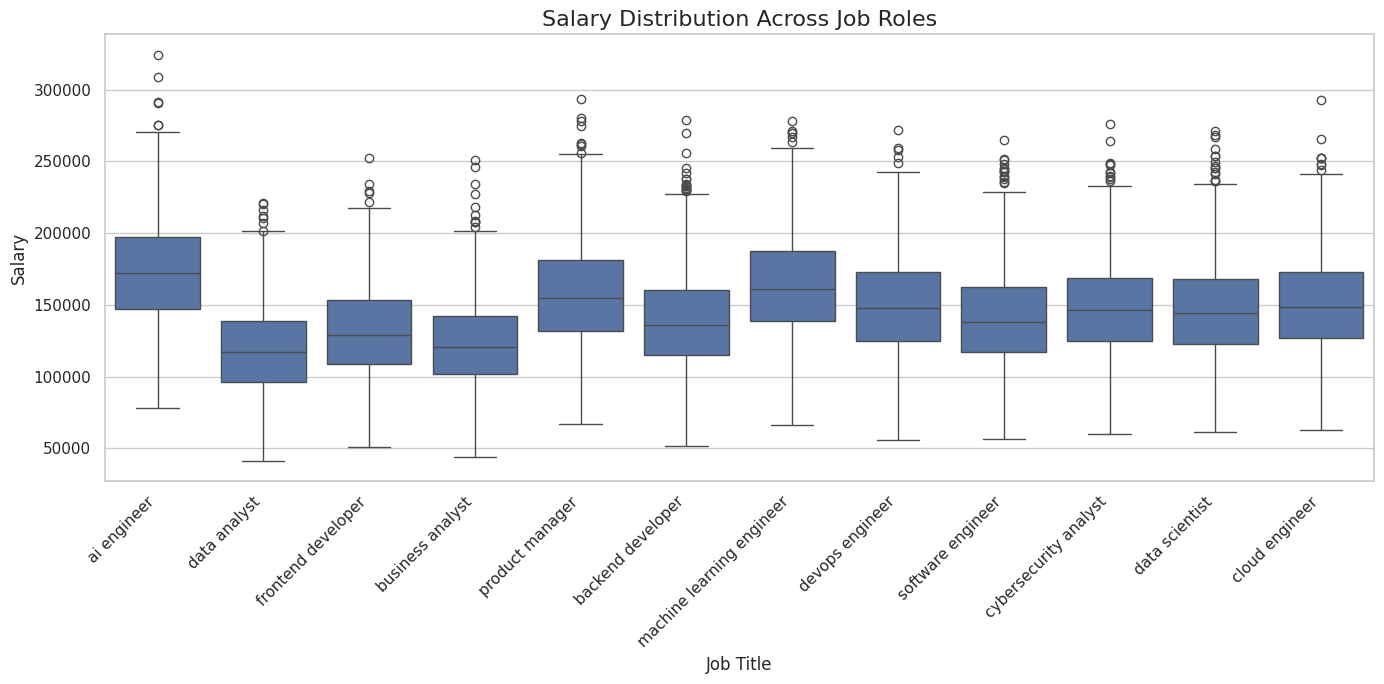

In [66]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="job_title",
    y="salary"
)

plt.title("Salary Distribution Across Job Roles", fontsize=16)
plt.xlabel("Job Title")
plt.ylabel("Salary")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

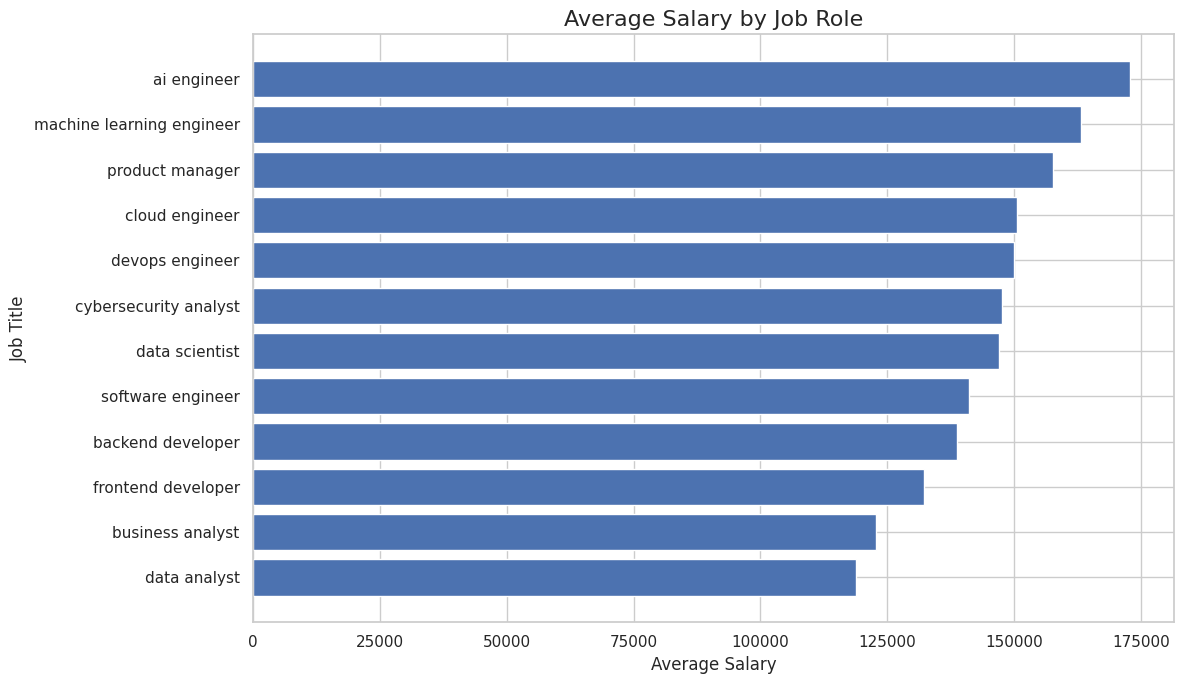

In [67]:
plt.figure(figsize=(12, 7))

salary_by_role = (
    df.groupby("job_title")["salary"]
    .mean()
    .sort_values(ascending=True)
)

plt.barh(
    salary_by_role.index,
    salary_by_role.values
)

plt.title("Average Salary by Job Role", fontsize=16)
plt.xlabel("Average Salary")
plt.ylabel("Job Title")

plt.tight_layout()
plt.show()

In [68]:
experience_salary = (
    df.groupby("experience_years")["salary"]
    .agg(
        employee_count="count",
        average_salary="mean",
        median_salary="median"
    )
)

experience_salary

,employee_count,average_salary,median_salary
experience_years,,,
0,721,119805.320388,117570.0
1,779,120764.302953,119101.0
2,709,124507.235543,121826.0
3,737,128023.208955,125516.0
4,733,129845.477490,127370.0
5,727,130256.797799,129106.0
6,725,135508.591724,133130.0
7,708,137088.848870,133589.0
8,719,139872.214186,138240.0


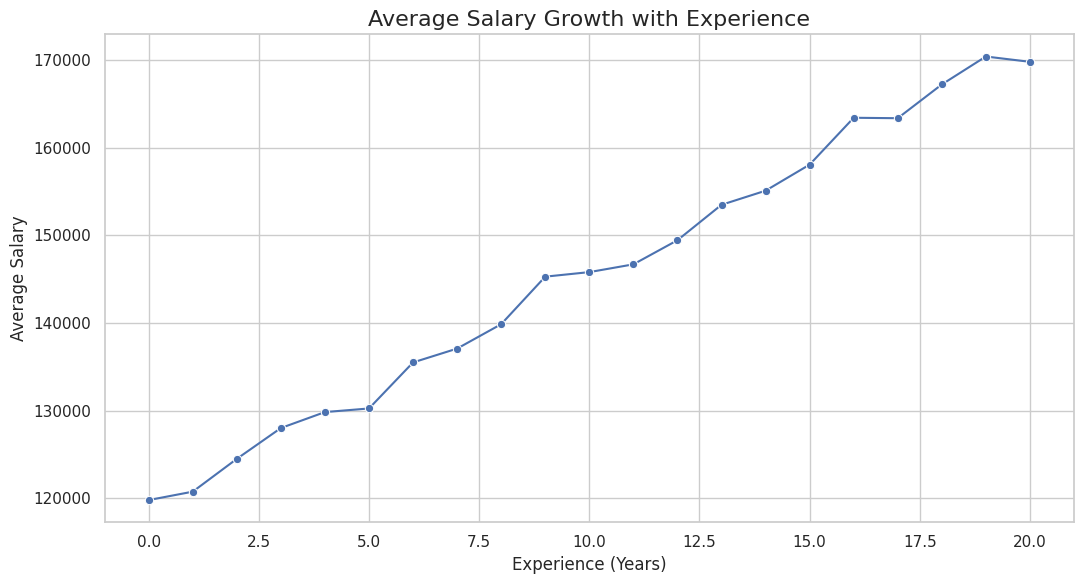

In [69]:
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=experience_salary,
    x=experience_salary.index,
    y="average_salary",
    marker="o"
)

plt.title("Average Salary Growth with Experience", fontsize=16)
plt.xlabel("Experience (Years)")
plt.ylabel("Average Salary")

plt.tight_layout()
plt.show()

In [70]:
first_salary = experience_salary.loc[
    experience_salary.index.min(),
    "average_salary"
]

last_salary = experience_salary.loc[
    experience_salary.index.max(),
    "average_salary"
]

growth_percentage = (
    (last_salary - first_salary) / first_salary
) * 100

print(f"Average salary growth from minimum to maximum experience: {growth_percentage:.2f}%")

Average salary growth from minimum to maximum experience: 41.74%


In [71]:
correlation = df["experience_years"].corr(df["salary"])

print(f"Correlation between experience and salary: {correlation:.4f}")

Correlation between experience and salary: 0.4283


In [72]:
location_salary = (
    df.groupby("location")["salary"]
    .agg(
        employee_count="count",
        average_salary="mean",
        median_salary="median",
        minimum_salary="min",
        maximum_salary="max"
    )
    .sort_values("average_salary", ascending=False)
)

location_salary

,employee_count,average_salary,median_salary,minimum_salary,maximum_salary
location,,,,,
usa,1479,181489.575389,180175.0,86417.0,324505.0
canada,1519,167444.878209,164582.0,78436.0,275172.0
uk,1568,159898.539541,158747.0,60519.0,280412.0
germany,1511,153676.733951,151486.0,77870.0,249334.0
remote,1557,139393.997431,138585.0,59539.0,241105.0
sweden,1508,139250.336870,137476.5,66884.0,236193.0
netherlands,1534,139130.304433,136057.5,62119.0,247558.0
singapore,1580,138787.022785,136755.0,52787.0,239894.0
australia,1539,137388.399610,134969.0,58576.0,239426.0


In [74]:
experience_salary = (
    df.groupby("experience_years")["salary"]
    .agg(
        employee_count="count",
        average_salary="mean",
        median_salary="median"
    )
)

experience_salary

,employee_count,average_salary,median_salary
experience_years,,,
0,721,119805.320388,117570.0
1,779,120764.302953,119101.0
2,709,124507.235543,121826.0
3,737,128023.208955,125516.0
4,733,129845.477490,127370.0
5,727,130256.797799,129106.0
6,725,135508.591724,133130.0
7,708,137088.848870,133589.0
8,719,139872.214186,138240.0


In [75]:
correlation = df["experience_years"].corr(df["salary"])

print(f"Correlation between experience and salary: {correlation:.4f}")

Correlation between experience and salary: 0.4283


In [76]:
location_salary = (
    df.groupby("location")["salary"]
    .agg(
        employee_count="count",
        average_salary="mean",
        median_salary="median",
        minimum_salary="min",
        maximum_salary="max"
    )
    .sort_values("average_salary", ascending=False)
)

location_salary

,employee_count,average_salary,median_salary,minimum_salary,maximum_salary
location,,,,,
usa,1479,181489.575389,180175.0,86417.0,324505.0
canada,1519,167444.878209,164582.0,78436.0,275172.0
uk,1568,159898.539541,158747.0,60519.0,280412.0
germany,1511,153676.733951,151486.0,77870.0,249334.0
remote,1557,139393.997431,138585.0,59539.0,241105.0
sweden,1508,139250.336870,137476.5,66884.0,236193.0
netherlands,1534,139130.304433,136057.5,62119.0,247558.0
singapore,1580,138787.022785,136755.0,52787.0,239894.0
australia,1539,137388.399610,134969.0,58576.0,239426.0


In [77]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X = df.drop(columns=["salary"])
y = df["salary"]

print("Features:", X.columns.tolist())
print("Target: salary")

Features: ['job_title', 'experience_years', 'education_level', 'skills_count', 'industry', 'company_size', 'location', 'remote_work', 'certifications']
Target: salary


In [78]:
numeric_features = [
    "experience_years",
    "skills_count",
    "certifications"
]

categorical_features = [
    "job_title",
    "education_level",
    "industry",
    "company_size",
    "location",
    "remote_work"
]

In [79]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numeric_features
        )
    ]
)

In [80]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

In [81]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 12223
Testing samples : 3056


In [82]:
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [84]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("===== LINEAR REGRESSION EVALUATION =====")
print(f"MAE  : {mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.4f}")

NameError: name 'y_pred' is not defined

In [85]:
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [86]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[118669.20692049 203437.86185098 163038.5296792  130096.60659043
 158956.11345327 115523.33770862 173099.31802116 114336.07199452
 148672.85344008 149945.77079772]


In [87]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("===== LINEAR REGRESSION EVALUATION =====")
print(f"MAE  : {mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.4f}")

===== LINEAR REGRESSION EVALUATION =====
MAE  : 5,290.35
MSE  : 47,826,224.87
RMSE : 6,915.65
R²   : 0.9650


In [88]:
# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("===== LINEAR REGRESSION RESULTS =====")
print(f"MAE  : {mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.4f}")

===== LINEAR REGRESSION RESULTS =====
MAE  : 5,290.35
MSE  : 47,826,224.87
RMSE : 6,915.65
R²   : 0.9650


In [89]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['job_title',
                                                   'education_level',
                                                   'industry', 'company_size',
                                                   'location', 'remote_work']),
                                                 ('numerical', 'passthrough',
                                                  ['experience_years',
                                                   'skills_count',
                                                   'certifications'])])),
                ('regressor', LinearRegression())])

In [90]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [91]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:5])

Predictions generated successfully!
[118669.20692049 203437.86185098 163038.5296792  130096.60659043
 158956.11345327]


In [92]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("===== LINEAR REGRESSION EVALUATION =====")
print(f"MAE  : {mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.4f}")

===== LINEAR REGRESSION EVALUATION =====
MAE  : 5,290.35
MSE  : 47,826,224.87
RMSE : 6,915.65
R²   : 0.9650
